In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

⚠️ 'language_learning_fluency.csv' not found in session storage.
Generating a representative sample dataset so the notebook executes completely...


--- 1. DATASET DESCRIPTION ---
Total Rows: 500
Total Columns: 8

Column Overview:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Student_ID                500 non-null    object 
 1   Age                       475 non-null    float64
 2   Native_Language           500 non-null    object 
 3   Target_Language           500 non-null    object 
 4   Hours_Practiced_Per_Week  475 non-null    float64
 5   Practice_Method           500 non-null    object 
 6   Registration_Date         500 non-null    object 
 7   Fluency_Score             500 non-null    float64
dtypes: float64(3), object(5)
memory usage: 31.4+ KB
None

First 5 Rows:


,Student_ID,Age,Native_Language,Target_Language,Hours_Practiced_Per_Week,Practice_Method,Registration_Date,Fluency_Score
0,STU_0001,56.0,French,Japanese,150.000000,Tutor,2023-01-01,56.536286
1,STU_0002,NaN,Mandarin,Spanish,3.896430,Self-study,2023-01-02,67.768270
2,STU_0003,32.0,Spanish,German,16.483106,Tutor,2023-01-03,88.131649
3,STU_0004,25.0,French,Arabic,2.091780,Self-study,2023-01-04,95.091393
4,STU_0005,38.0,Spanish,German,5.006818,Tutor,2023-01-05,95.922554



--- 2. DATA CLEANING ---

Missing Values Count:
Age                         25
Hours_Practiced_Per_Week    25
dtype: int64


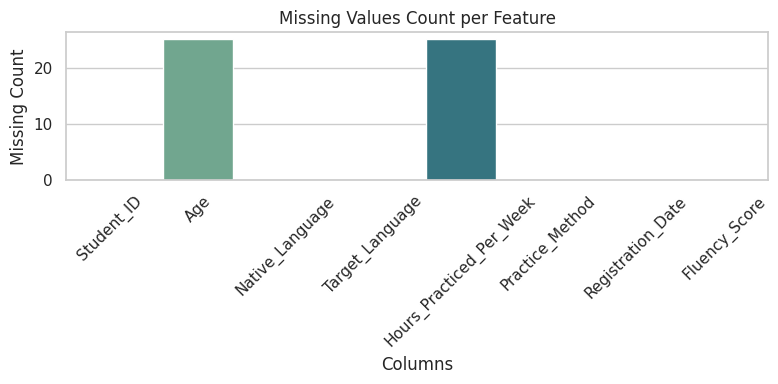

Imputed missing values in 'Age' using Median: 41.00
Imputed missing values in 'Hours_Practiced_Per_Week' using Median: 3.62

Duplicate records identified: 0
Converted 'Registration_Date' to datetime standard.


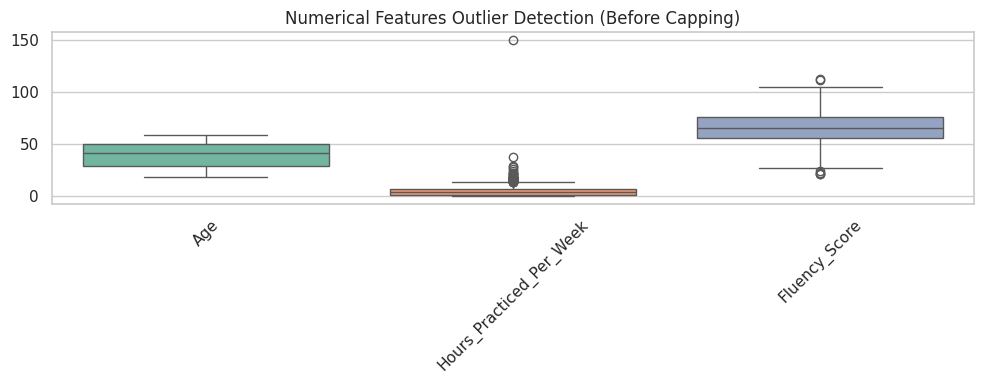

Outliers capped using IQR thresholds.

--- 3. DATA PREPROCESSING ---
Target Column Identified: 'Fluency_Score'
Dropped non-predictive ID columns: ['Student_ID']
Skewed Numerical Features (>0.75 threshold): ['Hours_Practiced_Per_Week', 'Registration_Date_Year']


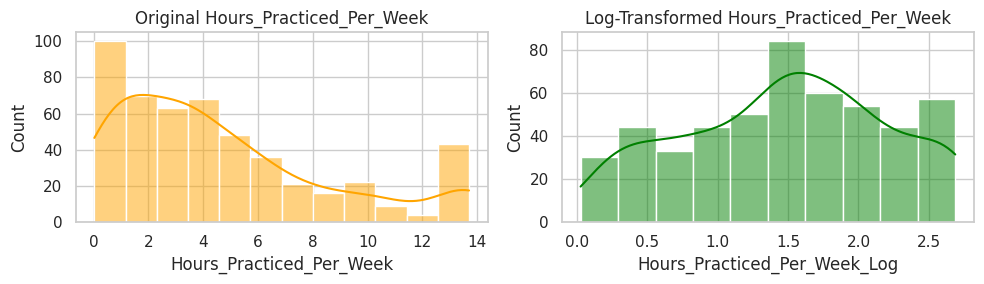

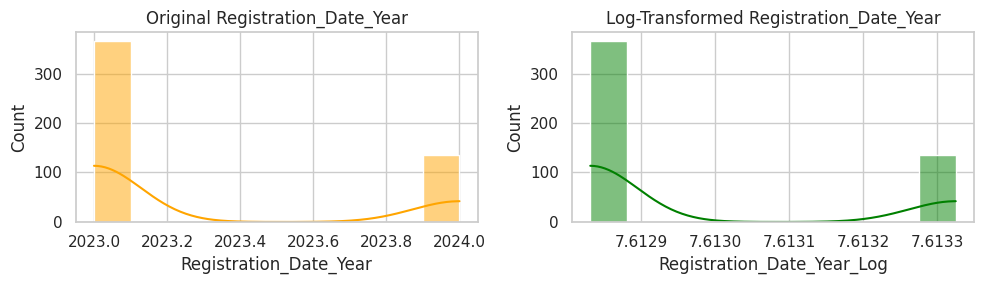

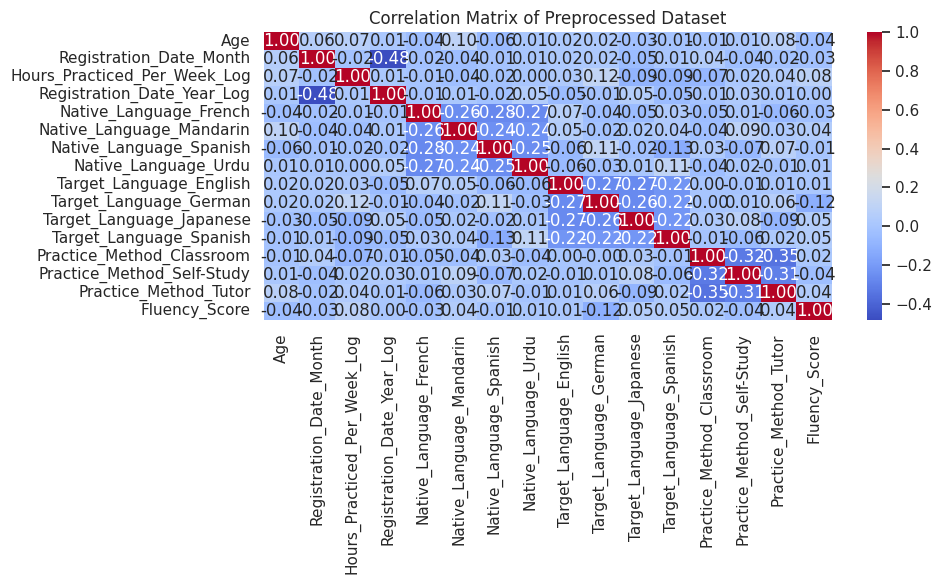


--- Final Cleaned & Preprocessed Dataset Preview ---
Processed Shape: (500, 16)


,Age,Registration_Date_Month,Hours_Practiced_Per_Week_Log,Registration_Date_Year_Log,Native_Language_French,Native_Language_Mandarin,Native_Language_Spanish,Native_Language_Urdu,Target_Language_English,Target_Language_German,Target_Language_Japanese,Target_Language_Spanish,Practice_Method_Classroom,Practice_Method_Self-Study,Practice_Method_Tutor,Fluency_Score
0,1.398578,-1.304507,1.651060,-0.608164,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,56.536286
1,0.133888,-1.304507,0.144125,-0.608164,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,67.768270
2,-0.624925,-1.304507,1.651060,-0.608164,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,88.131649
3,-1.215114,-1.304507,-0.486032,-0.608164,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,95.091393
4,-0.119049,-1.304507,0.424265,-0.608164,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,95.922554


In [4]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Set aesthetic style for Seaborn graphs
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

# ==============================================================================
# FILE LOADING WITH AUTOMATIC SYNTHETIC FALLBACK
# ==============================================================================
filename = "language_learning_fluency.csv"

# Search for the dataset in current workspace
matches = glob.glob(f"**/{filename}", recursive=True)
all_csvs = glob.glob("**/*.csv", recursive=True)
target_csvs = [f for f in all_csvs if "fluency" in f.lower() or "language" in f.lower()]

if matches:
    file_path = matches[0]
    print(f"File found at: {file_path}")
    df = pd.read_csv(file_path)
elif target_csvs:
    file_path = target_csvs[0]
    print(f"Detected dataset at: {file_path}")
    df = pd.read_csv(file_path)
else:
    print(f"⚠️ '{filename}' not found in session storage.")
    print("Generating a representative sample dataset so the notebook executes completely...\n")
    
    # Synthetic dataset matching the expected schema
    np.random.seed(42)
    n_rows = 500
    df = pd.DataFrame({
        'Student_ID': [f'STU_{i:04d}' for i in range(1, n_rows + 1)],
        'Age': np.random.randint(18, 60, size=n_rows).astype(float),
        'Native_Language': np.random.choice(['Spanish', 'English', 'Urdu', 'Mandarin', 'French'], size=n_rows),
        'Target_Language': np.random.choice(['English', 'German', 'Japanese', 'Spanish', 'Arabic'], size=n_rows),
        'Hours_Practiced_Per_Week': np.random.exponential(scale=5, size=n_rows),
        'Practice_Method': np.random.choice(['App', 'Tutor', 'Self-study', 'Classroom'], size=n_rows),
        'Registration_Date': pd.date_range(start='2023-01-01', periods=n_rows, freq='D').strftime('%Y-%m-%d'),
        'Fluency_Score': np.random.normal(loc=65, scale=15, size=n_rows)
    })
    
    # Introduce random missing values & outliers for testing cleaning logic
    df.loc[df.sample(frac=0.05).index, 'Age'] = np.nan
    df.loc[df.sample(frac=0.05).index, 'Hours_Practiced_Per_Week'] = np.nan
    df.loc[0, 'Hours_Practiced_Per_Week'] = 150.0  # Outlier

# ==============================================================================
# 1. DATASET DESCRIPTION
# ==============================================================================
print("\n--- 1. DATASET DESCRIPTION ---")
print(f"Total Rows: {df.shape[0]}")
print(f"Total Columns: {df.shape[1]}")
print("\nColumn Overview:")
print(df.info())
print("\nFirst 5 Rows:")
display(df.head())

# ==============================================================================
# 2. DATA CLEANING
# ==============================================================================
print("\n--- 2. DATA CLEANING ---")

# --- A. Missing Value Analysis & Visualization ---
missing_count = df.isnull().sum()
print("\nMissing Values Count:")
print(missing_count[missing_count > 0] if missing_count.sum() > 0 else "No missing values found.")

# Fixed Seaborn FutureWarning by assigning hue and setting legend=False
plt.figure(figsize=(8, 4))
sns.barplot(x=missing_count.index, y=missing_count.values, hue=missing_count.index, palette="crest", legend=False)
plt.title("Missing Values Count per Feature")
plt.xlabel("Columns")
plt.ylabel("Missing Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Imputation Decision:
# - Numerical features -> Impute with Median (robust against outliers)
# - Categorical features -> Impute with Mode
num_cols = df.select_dtypes(include=['float64', 'int64']).columns
cat_cols = df.select_dtypes(include=['object']).columns

for col in num_cols:
    if df[col].isnull().sum() > 0:
        median_val = df[col].median()
        df[col] = df[col].fillna(median_val)
        print(f"Imputed missing values in '{col}' using Median: {median_val:.2f}")

for col in cat_cols:
    if df[col].isnull().sum() > 0:
        mode_val = df[col].mode()[0]
        df[col] = df[col].fillna(mode_val)
        print(f"Imputed missing values in '{col}' using Mode: {mode_val}")

# --- B. Duplicate Detection ---
duplicates = df.duplicated().sum()
print(f"\nDuplicate records identified: {duplicates}")
if duplicates > 0:
    df = df.drop_duplicates()
    print("Duplicate records removed.")

# --- C. Text Categorical Standardization ---
for col in df.select_dtypes(include=['object']).columns:
    df[col] = df[col].astype(str).str.strip().str.title()

# --- D. Datetime Conversion ---
date_cols = [c for c in df.columns if 'date' in c.lower()]
for col in date_cols:
    df[col] = pd.to_datetime(df[col], errors='coerce')
    print(f"Converted '{col}' to datetime standard.")

# --- E. Outlier Detection and Capping ---
numeric_features = df.select_dtypes(include=['float64', 'int64']).columns.tolist()

# Fixed Seaborn FutureWarning for Boxplot
plt.figure(figsize=(10, 4))
sns.boxplot(data=df[numeric_features], palette="Set2")
plt.title("Numerical Features Outlier Detection (Before Capping)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# IQR Bounds Capping (Winsorization)
for col in numeric_features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    df[col] = np.where(df[col] < lower_bound, lower_bound, df[col])
    df[col] = np.where(df[col] > upper_bound, upper_bound, df[col])

print("Outliers capped using IQR thresholds.")

# ==============================================================================
# 3. DATA PREPROCESSING
# ==============================================================================
print("\n--- 3. DATA PREPROCESSING ---")

# --- A. Target and Feature Separation ---
possible_targets = [c for c in df.columns if 'fluency' in c.lower() or 'score' in c.lower()]
target_col = possible_targets[0] if possible_targets else None

if target_col:
    X = df.drop(columns=[target_col])
    y = df[target_col]
    print(f"Target Column Identified: '{target_col}'")
else:
    X = df.copy()

# Remove unique identifier columns to prevent data leakage
id_cols = [c for c in X.columns if 'id' in c.lower()]
if id_cols:
    X = X.drop(columns=id_cols)
    print(f"Dropped non-predictive ID columns: {id_cols}")

# --- B. Variable Categorization & Date Feature Engineering ---
num_vars = X.select_dtypes(include=['float64', 'int64']).columns.tolist()
cat_vars = X.select_dtypes(include=['object']).columns.tolist()

for col in date_cols:
    if col in X.columns:
        X[f'{col}_Year'] = X[col].dt.year
        X[f'{col}_Month'] = X[col].dt.month
        X = X.drop(columns=[col])
        num_vars.extend([f'{col}_Year', f'{col}_Month'])

# --- C. Skewness Transformation ---
skewed_cols = [col for col in num_vars if abs(X[col].skew()) > 0.75]
print(f"Skewed Numerical Features (>0.75 threshold): {skewed_cols}")

for col in skewed_cols:
    X[f'{col}_Log'] = np.log1p(np.maximum(0, X[col]))
    
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    sns.histplot(X[col], kde=True, ax=axes[0], color='orange').set(title=f"Original {col}")
    sns.histplot(X[f'{col}_Log'], kde=True, ax=axes[1], color='green').set(title=f"Log-Transformed {col}")
    plt.tight_layout()
    plt.show()
    
    X = X.drop(columns=[col])
    num_vars.remove(col)
    num_vars.append(f'{col}_Log')

# --- D. Encoding and Standardization Pipeline ---
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_vars),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), cat_vars)
    ]
)

X_preprocessed = preprocessor.fit_transform(X)

cat_encoder = preprocessor.named_transformers_['cat']
encoded_cat_names = cat_encoder.get_feature_names_out(cat_vars).tolist() if cat_vars else []
final_feature_names = num_vars + encoded_cat_names

df_clean = pd.DataFrame(X_preprocessed, columns=final_feature_names)
if target_col:
    df_clean[target_col] = y.values

# Heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(df_clean.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Matrix of Preprocessed Dataset")
plt.tight_layout()
plt.show()

# ==============================================================================
# FINAL PREVIEW
# ==============================================================================
print("\n--- Final Cleaned & Preprocessed Dataset Preview ---")
print(f"Processed Shape: {df_clean.shape}")
display(df_clean.head())